In [1]:
from pathlib import Path
import xml.etree.ElementTree as ET

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EVENTS_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\subsample_events.xml"
)

if not EVENTS_PATH.is_file():
    raise FileNotFoundError(f"File non trovato: {EVENTS_PATH}")

print(f"Dimensione: {EVENTS_PATH.stat().st_size / 1024**2:.1f} MiB")
print(f"Versione pandas: {pd.__version__}")

Dimensione: 157.3 MiB
Versione pandas: 3.1.0


In [2]:
def read_events_xml(path):
    records = []

    context = ET.iterparse(path, events=("start", "end"))
    _, root = next(context)

    for event, element in context:
        if event == "end" and element.tag == "row":
            records.append({
                child.tag: child.text
                for child in element
            })
            root.clear()

    return pd.DataFrame.from_records(records)


events_raw = read_events_xml(EVENTS_PATH)

print(f"Righe: {len(events_raw):,}")
print(f"Colonne: {len(events_raw.columns)}")
display(events_raw.head())

Righe: 716,643
Colonne: 6


,index,event_id,event_type,truth_id,user_id,timestamp
0,0,13564574,CR,2531,27,2022-04-28 17:29:00
1,1,14463475,CR,2778,177,2022-04-28 17:29:00
2,2,14473985,CR,3602,247,2022-04-28 17:29:00
3,3,14474918,CR,3687,251,2022-04-28 17:29:00
4,4,14492265,CR,3883,184,2022-04-28 17:29:00


In [3]:
events = events_raw.copy()

for column in events.columns:
    events[column] = events[column].astype("string").str.strip()

events = events.replace("", pd.NA)

profile = pd.DataFrame({
    "tipo": events.dtypes.astype(str),
    "mancanti": events.isna().sum(),
    "mancanti_pct": events.isna().mean().mul(100).round(2),
    "valori_distinti": events.nunique()
})

display(profile)
display(events.sample(5, random_state=42))

,tipo,mancanti,mancanti_pct,valori_distinti
index,string,0,0.0,716643
event_id,string,0,0.0,716643
event_type,string,0,0.0,4
truth_id,string,0,0.0,65433
user_id,string,0,0.0,26678
timestamp,string,0,0.0,714301


,index,event_id,event_type,truth_id,user_id,timestamp
148988,148988,26774339,REP,130407,4273,2022-07-26 16:31:51.855534590
459932,459948,17109404,RET,15127,230747,2022-07-19 12:58:04.825845305
229201,229201,30156993,LI,366931,8611,2022-06-07 18:50:20.429818294
442398,442398,131188623,RET,108211822140637685,3761,2023-11-01 17:31:43.192497320
26808,26808,22072039,LI,69023,12738,2022-07-16 13:09:27.918091995


In [4]:
id_columns = ["index", "event_id", "truth_id", "user_id"]

invalid_ids = {}

for column in id_columns:
    numeric = pd.to_numeric(events[column], errors="coerce")

    invalid = (
        events[column].notna()
        & (
            numeric.isna()
            | numeric.mod(1).ne(0)
        )
    )

    invalid_ids[column] = int(invalid.sum())
    events[column] = numeric.mask(invalid).astype("Int64")

events["timestamp_raw"] = events["timestamp"]

events["timestamp"] = pd.to_datetime(
    events["timestamp_raw"],
    format="mixed",
    errors="coerce"
)

invalid_timestamps = (
    events["timestamp_raw"].notna()
    & events["timestamp"].isna()
)

display(pd.Series(invalid_ids, name="ID non validi"))
print("Timestamp non interpretabili:", int(invalid_timestamps.sum()))

display(events.loc[
    invalid_timestamps,
    ["event_id", "timestamp_raw"]
].head(10))

events.info()

index       0
event_id    0
truth_id    0
user_id     0
Name: ID non validi, dtype: int64

Timestamp non interpretabili: 0


,event_id,timestamp_raw


<class 'pandas.DataFrame'>
RangeIndex: 716643 entries, 0 to 716642
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   index          716643 non-null  Int64         
 1   event_id       716643 non-null  Int64         
 2   event_type     716643 non-null  string        
 3   truth_id       716643 non-null  Int64         
 4   user_id        716643 non-null  Int64         
 5   timestamp      716643 non-null  datetime64[ns]
 6   timestamp_raw  716643 non-null  string        
dtypes: Int64(4), datetime64[ns](1), string(2)
memory usage: 41.0 MB


In [5]:
event_columns = [
    "event_id", "event_type", "truth_id", "user_id", "timestamp_raw"
]

quality_checks = pd.Series({
    "righe_duplicate_complete": int(
        events_raw.duplicated().sum()
    ),
    "eventi_duplicati_escluso_index": int(
        events.duplicated(subset=event_columns).sum()
    ),
    "ripetizioni_event_id": int(
        events["event_id"].dropna().duplicated().sum()
    ),
    "ripetizioni_index": int(
        events["index"].dropna().duplicated().sum()
    )
})

display(quality_checks)

display(
    events.loc[
        events["event_id"].notna()
        & events["event_id"].duplicated(keep=False)
    ].sort_values("event_id").head(20)
)

righe_duplicate_complete          0
eventi_duplicati_escluso_index    0
ripetizioni_event_id              0
ripetizioni_index                 0
dtype: int64

,index,event_id,event_type,truth_id,user_id,timestamp,timestamp_raw


,numero_eventi,percentuale
event_type,,
LI,459023,64.05
RET,171700,23.96
REP,83501,11.65
CR,2419,0.34


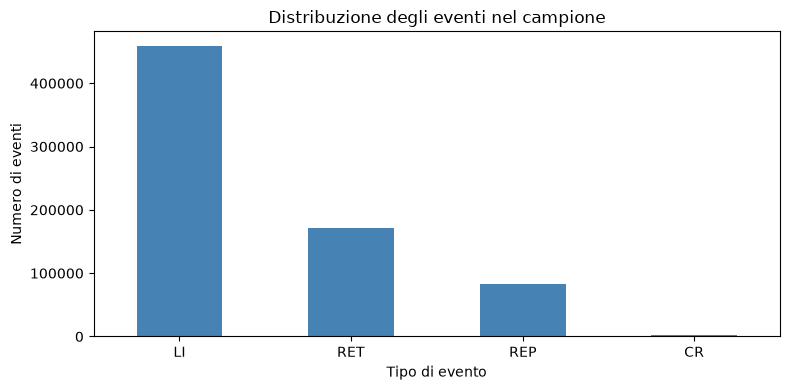

In [6]:
event_type_summary = (
    events["event_type"]
    .value_counts(dropna=False)
    .rename_axis("event_type")
    .to_frame("numero_eventi")
)

event_type_summary["percentuale"] = (
    event_type_summary["numero_eventi"]
    .div(len(events))
    .mul(100)
    .round(2)
)

display(event_type_summary)

event_type_summary["numero_eventi"].plot.bar(
    figsize=(8, 4),
    color="steelblue",
    rot=0
)

plt.title("Distribuzione degli eventi nel campione")
plt.xlabel("Tipo di evento")
plt.ylabel("Numero di eventi")
plt.tight_layout()
plt.show()

primo_evento                            2022-02-14 00:00:00
ultimo_evento                    2026-09-20 13:59:59.999999
timestamp_mancanti_o_invalidi                             0
giorni_con_eventi                                      1680
ordine_cronologico                                    False
dtype: object

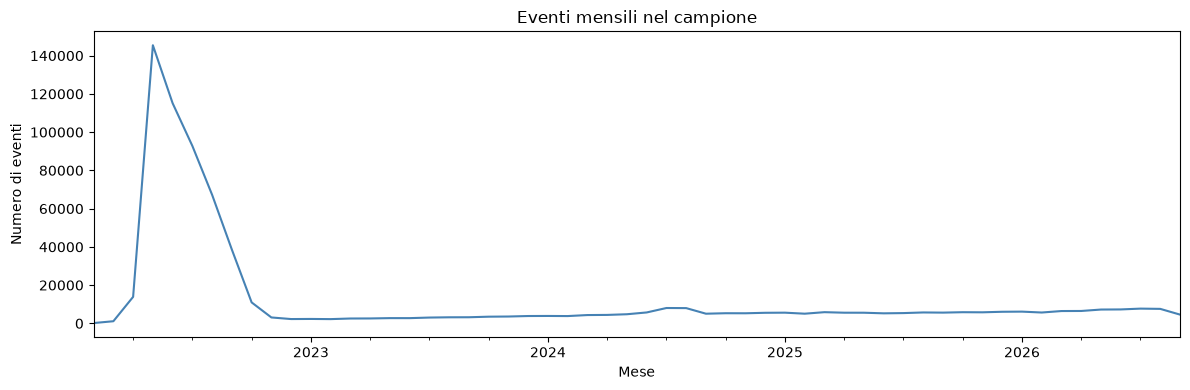

In [7]:
time_summary = pd.Series({
    "primo_evento": events["timestamp"].min(),
    "ultimo_evento": events["timestamp"].max(),
    "timestamp_mancanti_o_invalidi": events["timestamp"].isna().sum(),
    "giorni_con_eventi": events["timestamp"].dt.normalize().nunique(),
    "ordine_cronologico": events["timestamp"].is_monotonic_increasing
})

display(time_summary)

monthly_events = (
    events.dropna(subset=["timestamp"])
    .set_index("timestamp")
    .resample("MS")
    .size()
)

monthly_events.plot(
    figsize=(12, 4),
    color="steelblue"
)

plt.title("Eventi mensili nel campione")
plt.xlabel("Mese")
plt.ylabel("Numero di eventi")
plt.tight_layout()
plt.show()

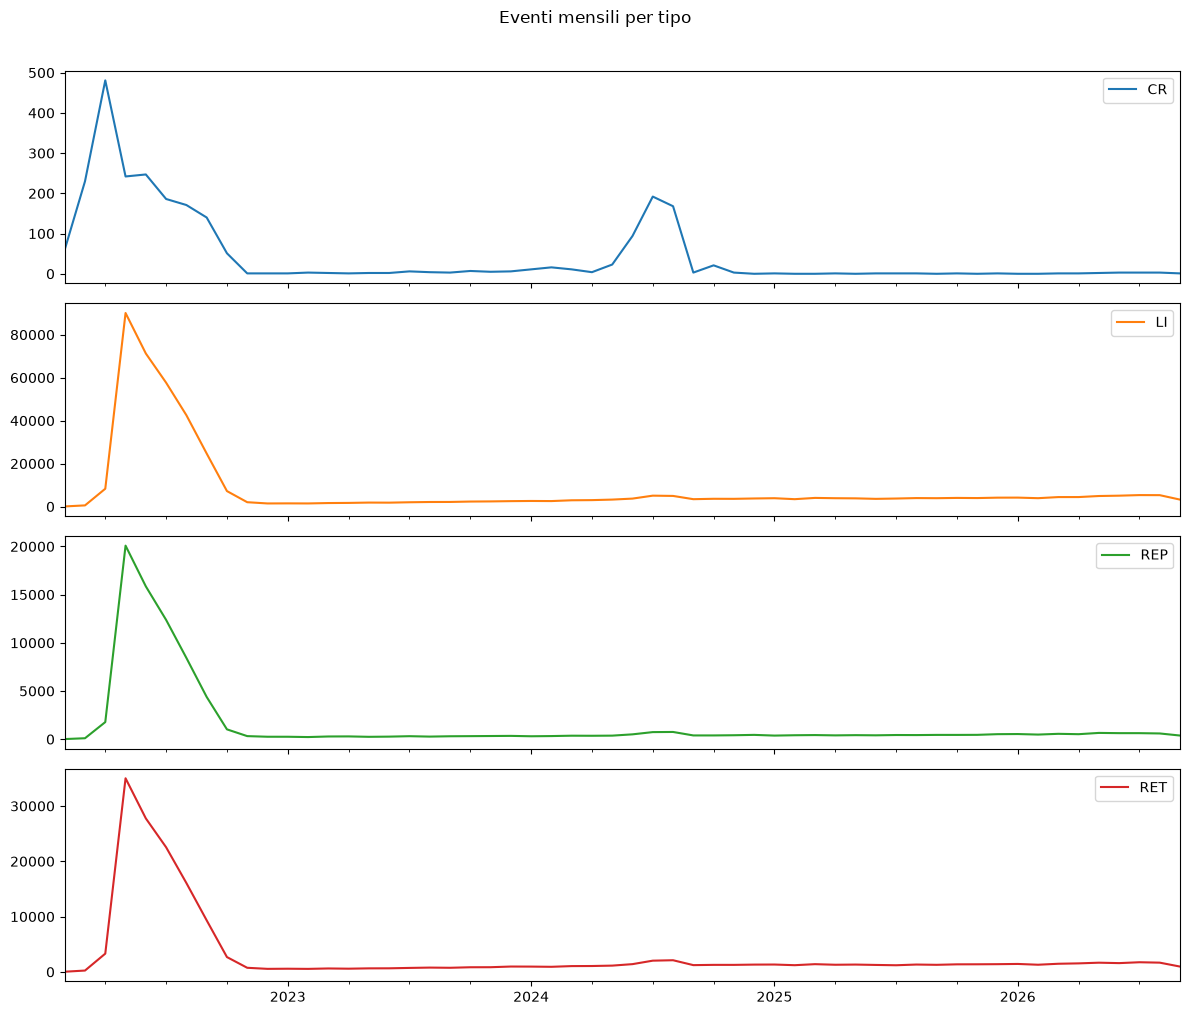

In [8]:
monthly_by_type = pd.crosstab(
    events["timestamp"].dt.to_period("M"),
    events["event_type"]
)

# Inserisce anche eventuali mesi senza eventi.
all_months = pd.period_range(
    events["timestamp"].min().to_period("M"),
    events["timestamp"].max().to_period("M"),
    freq="M"
)

monthly_by_type = monthly_by_type.reindex(
    all_months,
    fill_value=0
)

monthly_by_type.index = monthly_by_type.index.to_timestamp()

monthly_by_type.plot(
    subplots=True,
    figsize=(12, 10),
    sharex=True,
    legend=True
)

plt.suptitle("Eventi mensili per tipo", y=1.01)
plt.tight_layout()
plt.show()

In [9]:
display(pd.Series({
    "eventi": len(events),
    "utenti_distinti": events["user_id"].nunique(),
    "post_distinti": events["truth_id"].nunique()
}))

events_per_user = events.groupby("user_id").size()
events_per_truth = events.groupby("truth_id").size()

display(pd.DataFrame({
    "eventi_per_utente": events_per_user.describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ),
    "eventi_per_post": events_per_truth.describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
}))

print("Utenti con più eventi associati:")
display(events_per_user.nlargest(10).rename("numero_eventi"))

print("Post con più eventi associati:")
display(events_per_truth.nlargest(10).rename("numero_eventi"))

eventi             716643
utenti_distinti     26678
post_distinti       65433
dtype: int64

,eventi_per_utente,eventi_per_post
count,26678.000000,65433.000000
mean,26.862696,10.952318
std,832.400443,592.596794
min,1.000000,1.000000
50%,1.000000,2.000000
90%,5.000000,10.000000
95%,16.000000,12.000000
99%,218.230000,19.000000
max,106949.000000,50661.000000


Utenti con più eventi associati:


user_id
-1        106949
12967      50090
4273       30581
27         24501
230747     20394
12524      17551
438        16112
11363      15974
5881       13710
8256       12728
Name: numero_eventi, dtype: int64

Post con più eventi associati:


truth_id
69023                 50661
125307                50661
130407                50661
366255                50661
366931                50661
413805                50661
424756                50661
510621                50661
108211822140637685    49509
758728                   70
Name: numero_eventi, dtype: int64

Soglia esplorativa IQR: 13.50
Post oltre la soglia: 2,412


truth_id
413805                50661
510621                50661
424756                50661
130407                50661
366255                50661
69023                 50661
125307                50661
366931                50661
108211822140637685    49509
758728                   70
510629                   69
325285                   67
896293                   66
366261                   66
402472                   65
2764                     62
807654                   60
108789700493889917       58
112782066045321247       58
701630                   57
Name: numero_eventi, dtype: int64

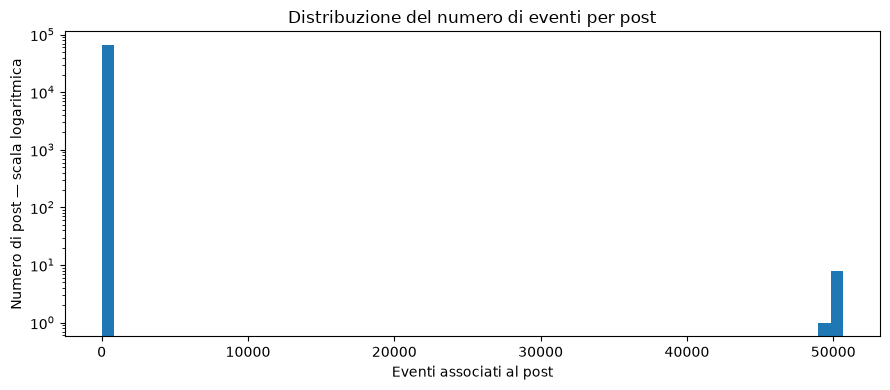

In [10]:
q1 = events_per_truth.quantile(0.25)
q3 = events_per_truth.quantile(0.75)
iqr = q3 - q1

upper_limit = q3 + 1.5 * iqr
high_activity_posts = events_per_truth[
    events_per_truth > upper_limit
].sort_values(ascending=False)

print(f"Soglia esplorativa IQR: {upper_limit:.2f}")
print(f"Post oltre la soglia: {len(high_activity_posts):,}")

display(high_activity_posts.head(20).rename("numero_eventi"))

plt.figure(figsize=(9, 4))
plt.hist(events_per_truth, bins=60)
plt.yscale("log")
plt.title("Distribuzione del numero di eventi per post")
plt.xlabel("Eventi associati al post")
plt.ylabel("Numero di post — scala logaritmica")
plt.tight_layout()
plt.show()

In [11]:
truth_ids = set(events["truth_id"].dropna())

truths_with_creation = set(
    events.loc[
        events["event_type"].eq("CR"),
        "truth_id"
    ].dropna()
)

truths_without_creation = truth_ids - truths_with_creation

display(pd.Series({
    "post_distinti": len(truth_ids),
    "post_con_CR_nel_campione": len(truths_with_creation),
    "post_senza_CR_nel_campione": len(truths_without_creation)
}))

creation_counts = (
    events.loc[events["event_type"].eq("CR")]
    .groupby("truth_id")
    .size()
)

print("Post con più di un evento CR:")
display(creation_counts[creation_counts > 1].head(20))

post_distinti                 65433
post_con_CR_nel_campione       2419
post_senza_CR_nel_campione    63014
dtype: int64

Post con più di un evento CR:


Series([], dtype: int64)

In [12]:
events["year"] = events["timestamp"].dt.year.astype("Int64")
events["month"] = events["timestamp"].dt.month.astype("Int64")
events["hour"] = events["timestamp"].dt.hour.astype("Int64")
events["day_of_week"] = (
    events["timestamp"].dt.dayofweek.astype("Int64")
)

events["time_band"] = pd.Series(
    pd.NA,
    index=events.index,
    dtype="string"
)

valid_time = events["timestamp"].notna()

night = (
    events["hour"].ge(20)
    | events["hour"].lt(8)
).fillna(False)

events.loc[valid_time & night, "time_band"] = "night"
events.loc[valid_time & ~night, "time_band"] = "day"

display(pd.crosstab(
    events["event_type"],
    events["time_band"],
    margins=True
))

C:\Users\bucco\AppData\Local\Temp\ipykernel_14752\1846393914.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  events["timestamp"].dt.dayofweek.astype("Int64")


time_band,day,night,All
event_type,,,
CR,1330,1089,2419
LI,228747,230276,459023
REP,41755,41746,83501
RET,85223,86477,171700
All,357055,359588,716643


In [15]:
# Inspect non-positive user identifiers without removing any events.
non_positive_user_events = events.loc[
    events["user_id"].notna()
    & events["user_id"].le(0)
]

print("Events associated with non-positive user IDs:")
display(
    pd.crosstab(
        non_positive_user_events["user_id"],
        non_positive_user_events["event_type"],
        margins=True
    )
)

display(
    non_positive_user_events[
        ["event_id", "event_type", "truth_id", "user_id", "timestamp"]
    ].head(5)
)

Events associated with non-positive user IDs:


event_type,LI,REP,RET,All
user_id,,,,
-1,68553,12568,25828,106949
All,68553,12568,25828,106949


,event_id,event_type,truth_id,user_id,timestamp
49,22045280,LI,69023,-1,2022-06-02 15:21:16.417385760
71,22045302,LI,69023,-1,2022-04-28 22:09:55.493601785
79,22045310,LI,69023,-1,2022-05-16 05:59:03.961251403
88,22045319,LI,69023,-1,2022-06-17 18:39:41.214065413
100,22045331,LI,69023,-1,2022-04-29 17:52:59.663323547


In [16]:
top_post_counts = events.groupby("truth_id").size().nlargest(10)

top_post_events = events.loc[
    events["truth_id"].isin(top_post_counts.index)
]

top_post_summary = (
    top_post_events
    .groupby("truth_id")
    .agg(
        event_count=("event_id", "size"),
        distinct_user_ids=("user_id", "nunique"),
        first_event=("timestamp", "min"),
        last_event=("timestamp", "max")
    )
    .join(
        pd.crosstab(
            top_post_events["truth_id"],
            top_post_events["event_type"]
        ).add_prefix("type_")
    )
    .sort_values("event_count", ascending=False)
)

display(top_post_summary)

,event_count,distinct_user_ids,first_event,last_event,type_CR,type_LI,type_REP,type_RET
truth_id,,,,,,,,
69023,50661,3125,2022-04-28 17:29:00.000000000,2022-09-22 03:11:40.608470840,1,31340,7137,12183
125307,50661,3005,2022-04-28 17:29:00.000000000,2022-09-27 23:33:41.318885822,1,31340,7137,12183
130407,50661,3017,2022-04-28 17:29:00.000000000,2022-09-28 00:08:33.929018738,1,31340,7137,12183
366255,50661,2908,2022-04-28 17:29:00.000000000,2022-10-12 05:19:13.086723164,1,31340,7137,12183
366931,50661,2820,2022-04-28 17:29:00.000000000,2022-10-11 20:30:51.366130222,1,31340,7137,12183
413805,50661,2963,2022-04-28 17:29:00.000000000,2022-10-13 06:11:40.932804668,1,31340,7137,12183
424756,50661,2807,2022-04-28 17:29:00.000000000,2022-10-14 12:53:46.204487602,1,31340,7137,12183
510621,50661,3013,2022-04-28 17:29:00.000000000,2022-10-17 18:54:09.729392960,1,31340,7137,12183
108211822140637685,49509,4981,2022-04-28 21:29:28.000000000,2026-09-09 09:37:58.001953496,1,30969,6723,11816


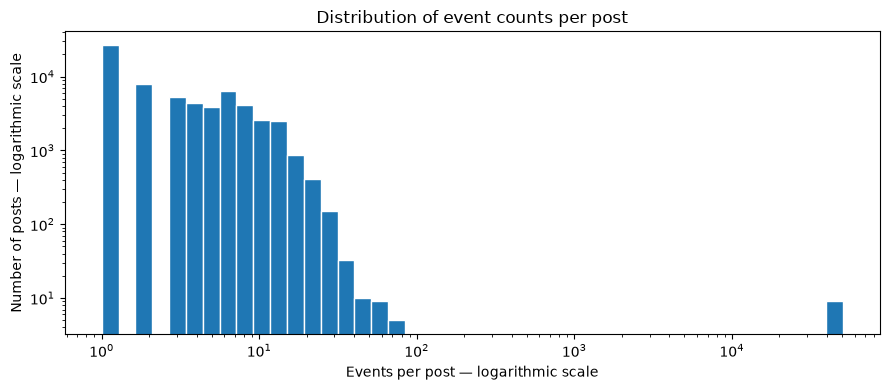

In [18]:

import numpy as np 

post_event_counts = events.groupby("truth_id").size()

bins = np.geomspace(
    1,
    post_event_counts.max() + 1,
    num=45
)

plt.figure(figsize=(9, 4))
plt.hist(post_event_counts, bins=bins, edgecolor="white")
plt.xscale("log")
plt.yscale("log")

plt.title("Distribution of event counts per post")
plt.xlabel("Events per post — logarithmic scale")
plt.ylabel("Number of posts — logarithmic scale")
plt.tight_layout()
plt.show()

In [19]:
# Flag the unresolved user identifier without changing source values.
events["has_unresolved_user"] = events["user_id"].eq(-1).fillna(False)

user_id_summary = pd.Series({
    "total_events": len(events),
    "events_with_user_id_minus_one": int(
        events["has_unresolved_user"].sum()
    ),
    "percentage_with_user_id_minus_one": (
        events["has_unresolved_user"].mean() * 100
    )
})

display(user_id_summary)

# Exclude -1 only from this individual-user ranking.
user_event_ranking = (
    events.loc[
        events["user_id"].notna()
        & ~events["has_unresolved_user"]
    ]
    .groupby("user_id")
    .size()
    .sort_values(ascending=False)
    .rename("event_count")
)

display(user_event_ranking.head(10))

total_events                         716643.000000
events_with_user_id_minus_one        106949.000000
percentage_with_user_id_minus_one        14.923609
dtype: float64

user_id
12967     50090
4273      30581
27        24501
230747    20394
12524     17551
438       16112
11363     15974
5881      13710
8256      12728
71919     12559
Name: event_count, dtype: int64

In [20]:
post_event_counts = events.groupby("truth_id").size()

# Diagnostic group based on the large gap observed in this sample.
# This threshold is not a deletion rule.
extreme_post_ids = post_event_counts.loc[
    post_event_counts > 1000
].index

events["belongs_to_extreme_post"] = (
    events["truth_id"].isin(extreme_post_ids)
)

concentration_summary = pd.Series({
    "extreme_post_count": len(extreme_post_ids),
    "events_on_extreme_posts": int(
        events["belongs_to_extreme_post"].sum()
    ),
    "percentage_of_all_events": (
        events["belongs_to_extreme_post"].mean() * 100
    )
})

display(concentration_summary)

display(
    pd.crosstab(
        events["belongs_to_extreme_post"],
        events["event_type"],
        margins=True
    )
)

extreme_post_count               9.000000
events_on_extreme_posts     454797.000000
percentage_of_all_events        63.462142
dtype: float64

event_type,CR,LI,REP,RET,All
belongs_to_extreme_post,,,,,
False,2410,177334,19682,62420,261846
True,9,281689,63819,109280,454797
All,2419,459023,83501,171700,716643


## Connecting with truths.csv

In [21]:
from pathlib import Path

TRUTHS_PATH = EVENTS_PATH.parent / "truths.csv"

if not TRUTHS_PATH.is_file():
    raise FileNotFoundError(f"File not found: {TRUTHS_PATH}")

truth_columns = [
    "id",
    "author",
    "timestamp",
    "time_scraped",
    "like_count",
    "reply_count",
    "retruth_count",
    "is_retruth",
    "is_reply",
    "truth_retruthed",
    "text"
]

truth_reference = pd.read_csv(
    TRUTHS_PATH,
    usecols=truth_columns,
    dtype="string",
    encoding="utf-8-sig",
    keep_default_na=False
)

for column in truth_reference.columns:
    truth_reference[column] = (
        truth_reference[column]
        .str.strip()
        .replace("", pd.NA)
    )

print(f"Post records loaded: {len(truth_reference):,}")

Post records loaded: 1,051,149


In [22]:
def normalize_id_text(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0+$", "", regex=True)
        .replace("", pd.NA)
    )


truth_reference["truth_id_key"] = normalize_id_text(
    truth_reference["id"]
)

post_event_counts = events.groupby("truth_id").size()

extreme_post_counts = (
    post_event_counts.loc[post_event_counts > 1000]
    .sort_values(ascending=False)
)

extreme_post_keys = normalize_id_text(
    pd.Series(extreme_post_counts.index, dtype="string")
)

selected_truths = truth_reference.loc[
    truth_reference["truth_id_key"].isin(extreme_post_keys)
].copy()

match_counts = selected_truths.groupby("truth_id_key").size()

reference_check = pd.DataFrame({
    "truth_id_key": extreme_post_keys.to_numpy(),
    "event_count": extreme_post_counts.to_numpy()
})

reference_check["matching_post_records"] = (
    reference_check["truth_id_key"]
    .map(match_counts)
    .fillna(0)
    .astype(int)
)

reference_check["reference_status"] = (
    reference_check["matching_post_records"]
    .map(lambda count: (
        "missing" if count == 0
        else "unique" if count == 1
        else "ambiguous"
    ))
)

display(reference_check)

,truth_id_key,event_count,matching_post_records,reference_status
0,69023,50661,1,unique
1,125307,50661,2,ambiguous
2,130407,50661,2,ambiguous
3,366255,50661,1,unique
4,366931,50661,1,unique
5,413805,50661,2,ambiguous
6,424756,50661,2,ambiguous
7,510621,50661,2,ambiguous
8,108211822140637685,49509,0,missing
